# Bank Risk Lab: credit and market risk under economic regimes

How much can a bank lose in a bad year, and what does expected loss hide?
This notebook models a portfolio of 100 loans and a 100,000 PLN stock position,
and compares a model with independent risks to one where both depend on the
state of the economy.

## Key findings

- **Expected credit loss is about 9,000 PLN in both models**, yet the bank's risk is very different.
- **VaR 99% of total losses rises from 44,839 PLN to 71,815 PLN (+60%)** when loans and stocks share a common economic factor: in a bad year they lose at the same time.
- **Only 16.1% of fraud alarms are real frauds**, even though the system catches 95% of frauds, because honest transactions vastly outnumber fraudulent ones.

## Contents

1. Setup and assumptions
2. Credit risk: how many loans default?
3. Fraud alarms: how reliable is an alarm?
4. Market risk: stock price after one year
5. The bank in two worlds
6. Conclusions and limitations

In [2]:
n_loans = 100
p_d = 0.02
transactions = 10_000
prevalence = 0.01
sensitivity = 0.95
f_p_ratio = 0.05

TWO_REGIMES = {
    "good": {"prob": 0.8, "p_default": 0.01, "p_up": 0.51},
    "bad":  {"prob": 0.2, "p_default": 0.06, "p_up": 0.46},
}
INDEPENDENT = {"all": {"prob": 1.0, "p_default": 0.02, "p_up": 0.5}}

PORTFOLIO = {
    "n_loans": 100,
    "ead": 10_000,
    "lgd": 0.45,
    "position_value": 100_000,
    "n_days": 250,
}

s0, n_days, p_up = 100, 250, 0.5


In [14]:
import sys
sys.path.append("..")
import os
from simulations.credit import default_count_pmf,prob_at_least_one_default,prob_at_least_k_defaults,expected_credit_loss
from simulations.fraud import expected_alarm_counts,posterior_fraud_given_alarm
from simulations.market import stock_price_distribution
from simulations.bank_risk import simulate_bank_losses,risk_metrics

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

COLOR_INDEPENDENT = "#2E86AB"
COLOR_REGIMES = "#E07A1F"
COLOR_GREY = "#B0B7BF"

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

## Credit risk - how many loans default?

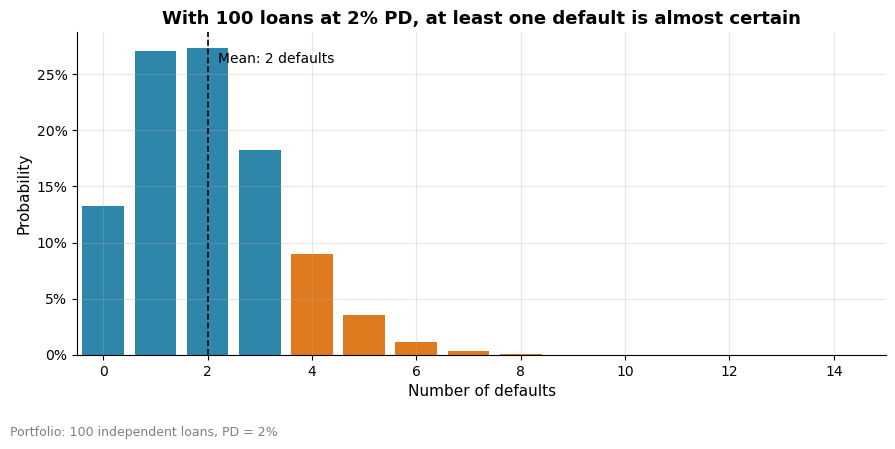

In [17]:
pmf = default_count_pmf(100, 0.02)
k = np.arange(len(pmf))
defaults_mean = np.sum(pmf * k)


colors = ["#E07A1F" if p < 0.10 else "#2E86AB" for p in pmf]
plt.bar(k, pmf, color=colors)


plt.axvline(defaults_mean, color="black", linestyle="--", linewidth=1.2)
plt.text(defaults_mean + 0.2, pmf.max() * 0.95,
         f"Mean: {defaults_mean:.0f} defaults", fontsize=10)
plt.xlim(-0.5, 15)
plt.title("With 100 loans at 2% PD, at least one default is almost certain",
          fontsize=13, fontweight="bold")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.xlabel("Number of defaults", fontsize=11)
plt.ylabel("Probability", fontsize=11)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2)
plt.figtext(0.01, 0.02, "Portfolio: 100 independent loans, PD = 2%",
            fontsize=9, color="grey")
plt.show()

In [18]:
p_at_least_1 = prob_at_least_one_default(100, 0.02)
p_at_least_5 = prob_at_least_k_defaults(100, 0.02, 5)
el = expected_credit_loss(100, 0.02, 10_000, 0.45)

print(f"P(at least 1 default):  {p_at_least_1:.1%}")
print(f"P(at least 5 defaults): {p_at_least_5:.1%}")
print(f"Expected credit loss:   {el:,.0f} PLN")

P(at least 1 default):  86.7%
P(at least 5 defaults): 5.1%
Expected credit loss:   9,000 PLN


## Fraud alarms: how reliable is an alarm?

In [20]:
counts = expected_alarm_counts(transactions, prevalence, sensitivity, f_p_ratio)

matrix = pd.DataFrame(
    {
        "Alarm": [counts["fraud_alarm"], counts["honest_alarm"]],
        "No alarm": [counts["fraud_no_alarm"], counts["honest_no_alarm"]],
    },
    index=["Fraud", "Honest"],
)
matrix["Total"] = matrix.sum(axis=1)
matrix.loc["Total"] = matrix.sum()

matrix.style.format("{:,.0f}")

,Alarm,No alarm,Total
Fraud,95,5,100
Honest,495,"9,405","9,900"
Total,590,"9,410","10,000"


In [21]:
p = posterior_fraud_given_alarm(prevalence, sensitivity, f_p_ratio)
print(f"Only {p:.1%} of alarms are real frauds "
      f"({counts['fraud_alarm']:,.0f} out of {counts['fraud_alarm'] + counts['honest_alarm']:,.0f}).")

Only 16.1% of alarms are real frauds (95 out of 590).


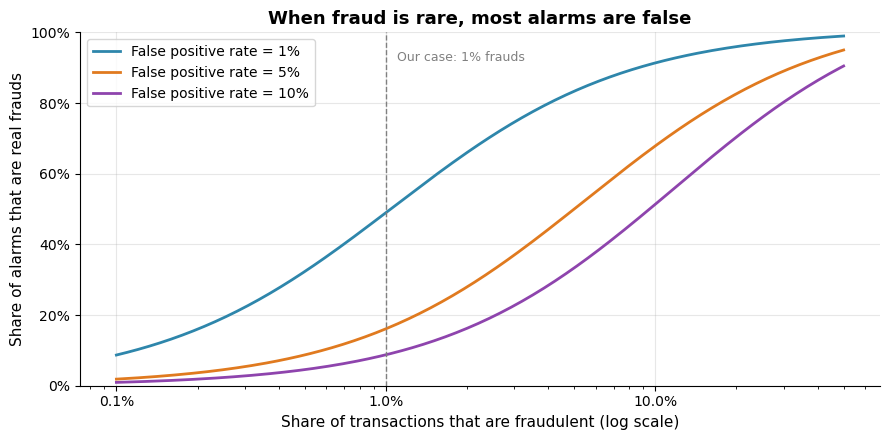

In [22]:
prevalences = np.logspace(-3, np.log10(0.5), 200)      
fp_rates = [0.01, 0.05, 0.10]
colors = ["#2E86AB", "#E07A1F", "#8E44AD"]

for fpr, color in zip(fp_rates, colors):
    posteriors = [posterior_fraud_given_alarm(p, sensitivity, fpr) for p in prevalences]
    plt.plot(prevalences, posteriors, color=color, linewidth=2,
             label=f"False positive rate = {fpr:.0%}")

plt.axvline(prevalence, color="grey", linestyle="--", linewidth=1)
plt.text(prevalence * 1.1, 0.92, f"Our case: {prevalence:.0%} frauds", fontsize=9, color="grey")

plt.xscale("log")
plt.gca().xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.ylim(0, 1)
plt.title("When fraud is rare, most alarms are false", fontsize=13, fontweight="bold")
plt.xlabel("Share of transactions that are fraudulent (log scale)", fontsize=11)
plt.ylabel("Share of alarms that are real frauds", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## Market risk: stock price after one year

In [28]:
prices, probs = stock_price_distribution(s0, n_days, p_up)

expected_price = np.sum(prices * probs)
most_likely_price = prices[np.argmax(probs)]
p_loss = probs[prices < s0].sum()

print(f"Expected price:     {expected_price:.2f}")
print(f"Most likely price:  {most_likely_price:.2f}")
print(f"P(price below 100): {p_loss:.1%}")

Expected price:     100.00
Most likely price:  98.76
P(price below 100): 52.5%


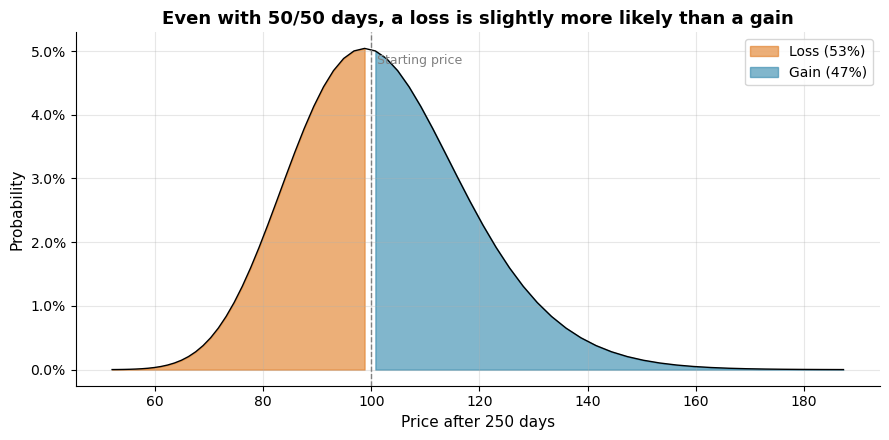

In [29]:
mask = probs > 1e-5              
x, y = prices[mask], probs[mask]

plt.plot(x, y, color="black", linewidth=1)
plt.fill_between(x, y, where=x < s0, color="#E07A1F", alpha=0.6, label=f"Loss ({p_loss:.0%})")
plt.fill_between(x, y, where=x >= s0, color="#2E86AB", alpha=0.6, label=f"Gain ({1 - p_loss:.0%})")
plt.axvline(s0, color="grey", linestyle="--", linewidth=1)
plt.text(s0 + 1, y.max() * 0.95, "Starting price", fontsize=9, color="grey")

plt.title("Even with 50/50 days, a loss is slightly more likely than a gain",
          fontsize=13, fontweight="bold")
plt.xlabel("Price after 250 days", fontsize=11)
plt.ylabel("Probability", fontsize=11)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
models = {
    "Independent": simulate_bank_losses(INDEPENDENT, **PORTFOLIO, seed=42),
    "Economic regimes": simulate_bank_losses(TWO_REGIMES, **PORTFOLIO, seed=42),
}

rows = [{"Model": m, "Part": part, **risk_metrics(losses[part])}
        for m, losses in models.items() for part in ["credit", "market", "total"]]

pd.DataFrame(rows).set_index(["Model", "Part"]).style.format("{:,.0f} PLN")

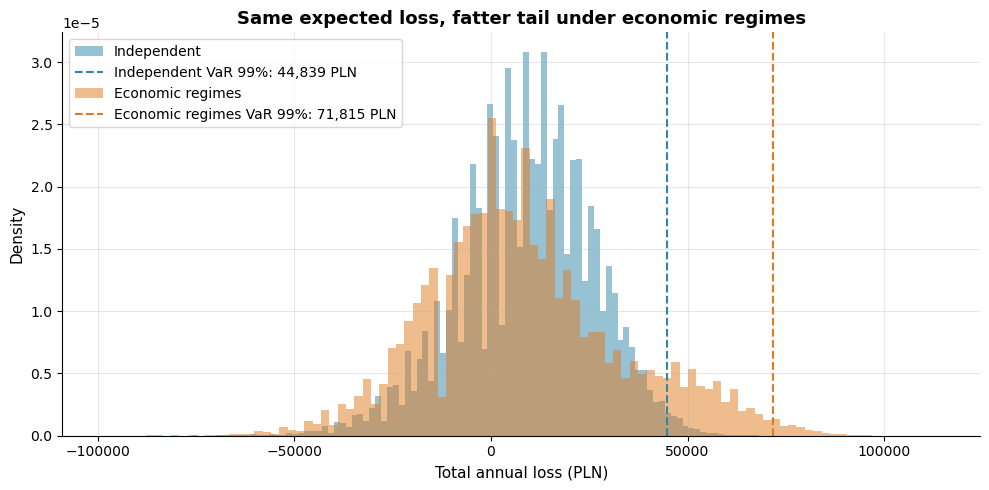

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
for (model, losses), color in zip(models.items(), ["#2E86AB", "#E07A1F"]):
    var = risk_metrics(losses["total"])["VaR"]
    ax.hist(losses["total"], bins=100, density=True, alpha=0.5, color=color, label=model)
    ax.axvline(var, color=color, linestyle="--", label=f"{model} VaR 99%: {var:,.0f} PLN")

ax.set_title("Same expected loss, fatter tail under economic regimes", fontweight="bold")
ax.set_xlabel("Total annual loss (PLN)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
os.makedirs("../images", exist_ok=True)
fig.savefig("../images/loss_distribution.png", dpi=150)
plt.show()

In [32]:
good = expected_credit_loss(100, 0.01, 10_000, 0.45)
bad = expected_credit_loss(100, 0.06, 10_000, 0.45)
print(f"Good year: {good:,.0f} PLN | Bad year: {bad:,.0f} PLN | "
      f"Weighted: {0.8 * good + 0.2 * bad:,.0f} PLN")

Good year: 4,500 PLN | Bad year: 27,000 PLN | Weighted: 9,000 PLN
